# 05b — Economic Frictions: Costs, Funding and Leverage (Phase 1 validation)

Notebook 05 ran every strategy with one set of frictions: 10 bp linear costs, a free initial
build, and borrowing at the EUR overnight rate with **no spread**. This notebook checks the
engine's accounting and then varies each friction **with the target weights held fixed**
(cached from notebook 04). Weights are never re-optimised here, so any change in results comes
from the frictions alone.

## Accounting (implemented in `src/backtest.py`, tested in `tests/test_backtest_accounting.py`)

Weights $w$ are fractions of NAV after the trade at the previous close. Cash weight $c = 1-\sum_i w_i$ (borrowed if negative). For day $d$:

$$
\begin{aligned}
TC_d &= NAV^{open}_d \sum_i k_i\,\lvert w_i^{new}-w_i^{pre}\rvert \qquad\text{(rebalance days only)}\\
NAV^{inv}_d &= NAV^{open}_d - TC_d\\
NAV^{close}_d &= NAV^{inv}_d\Big[1+\underbrace{\textstyle\sum_i w_i r_{i,d}}_{\text{assets}} + \underbrace{c^+ r^{cash}_d}_{\text{cash interest}} - \underbrace{c^-\big(r^{cash}_d + s\,\tfrac{\Delta days}{360}\big)}_{\text{funding}}\Big]
\end{aligned}
$$

* **Gross return** $= NAV^{close}/NAV^{inv}-1$: before transaction costs, after cash interest and funding.
* **Net return** $= NAV^{close}/NAV^{open}-1 = (1-TC/NAV^{open})(1+\text{gross})-1$.
* **Turnover** is **two-way**: $TO_t=\sum_i\lvert w^{target}_{i,t}-w^{pre}_{i,t}\rvert$ (traded notional / NAV); one-way $=\tfrac12 TO_t$. The initial build from cash is reported separately and is not part of turnover p.a.
* **Exposure:** gross $L_t=\sum_i\lvert w_i\rvert$; all strategies are long-only, so borrowed / NAV $=\max(L_t-1,0)$.
* **Limited liability:** NAV is floored at 0. If it hits 0, the strategy stays dead. No strategy here comes close.

**Assumptions vs. observations.** All cost and spread levels below are **scenario
assumptions**. None of them is an observed historical transaction cost. FX hedge roll costs are
still zero (Phase 4).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import data_loader as dl, risk as K, backtest as B

PROC = ROOT / "data" / "processed"
OUT = ROOT / "results" / "frictions"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
COL = {"60/40": "#2a78d6", "EW": "#eb6834", "RiskParity*": "#1baf7a", "MinVar": "#eda100",
       "MinVar*": "#e87ba4", "RiskParity": "#008300", "CVaR": "#6250d6", "MV-hist": "#e34948", "CVaR*": "#52514e"}

fc = K.load_forecasts(PROC / "cov_forecasts.npz")
A = fc["assets"]
daily = pd.read_csv(PROC / "asset_returns_eur_daily.csv", index_col="date", parse_dates=True)[A]
cash = B.daily_cash_returns(daily.index, dl.load_short_rates()["EUR"])
BASE = ["EW", "60/40", "MinVar", "RiskParity", "CVaR", "MV-hist"]
W = {m: pd.read_csv(PROC / "weights" / f"weights_{m.replace('/', '')}.csv", index_col=0, parse_dates=True)[A] for m in BASE}
LEVERED = ["MinVar", "RiskParity", "CVaR"]
ORDER = ["60/40", "EW", "MV-hist", "RiskParity*", "RiskParity", "CVaR*", "CVaR", "MinVar*", "MinVar"]
SAMPLE = "OOS 2010-05-03 – 2026-09-30, EUR, monthly rebalancing"

def dodge(ys, gap):
    # spread label y-positions so neighbours are at least `gap` apart (order preserved)
    order = np.argsort(ys); out = np.array(ys, float)
    for a, b in zip(order[:-1], order[1:]):
        if out[b] - out[a] < gap:
            out[b] = out[a] + gap
    return out

def lev_path(m, cap=5.0):
    return B.vol_target_leverage(W[m], fc["cov1w"]["GARCH-CCC"], W["60/40"], cap=cap)

def run(name, cost=10.0, charge_initial=True, spread=0.0, cap=5.0):
    base = name.rstrip("*")
    lev = lev_path(base, cap) if name.endswith("*") else None
    return B.run_backtest(daily, W[base], cash, cost, leverage=lev, charge_initial=charge_initial,
                          funding_spread_bps=spread)

def monthly_excess(r):
    return (1 + r).resample("ME").prod() - (1 + cash.reindex(r.index)).resample("ME").prod()

def stats(res, ref=None):
    s = B.perf_stats(res.net, cash, res.turnover, res.cost)
    L = res.ledger
    yrs = (L.index[-1] - L.index[0]).days / 365.25
    inv = L.nav_open - L.tc
    out = {"CAGR %": 100 * s["ann. return"], "vol %": 100 * s["ann. vol"], "Sharpe": s["Sharpe"],
           "Sortino": s["Sortino"], "MDD %": 100 * s["max drawdown"], "ES95 1d %": 100 * s["ES95 1d"],
           "TO 2-way p.a.": s["turnover p.a."], "TC bp p.a.": 1e4 * (L.tc / L.nav_open).sum() / yrs,
           "funding % p.a.": 100 * (L.funding_cost / inv).sum() / yrs,
           "avg gross exp.": L.gross_exposure.mean(), "avg borrowed": L.borrowed.mean()}
    if ref is not None:
        out["Memmel p vs 60/40"] = B.memmel_test(monthly_excess(res.net), monthly_excess(ref.net))[1]
    return out

## 1. Engine checks on the real portfolios

In [2]:
stored = pd.read_csv(PROC / "backtest_daily_net.csv", index_col=0, parse_dates=True)
rows = {}
for m in ORDER:
    legacy = run(m, charge_initial=False)                       # notebook-05 settings
    L = legacy.ledger
    resid = (L.nav_close - (L.nav_open - L.tc + L.pnl_assets + L.pnl_cash - L.funding_cost)).abs().max()
    chain = (L.nav_open.iloc[1:].to_numpy() - L.nav_close.iloc[:-1].to_numpy()).__abs__().max()
    rows[m] = {"max |net − stored|": (legacy.net - stored[m]).abs().max(), "identity residual": resid,
               "NAV chain residual": chain, "min NAV": L.nav_close.min(), "max gross exp.": L.gross_exposure.max(),
               "initial TO": legacy.initial_turnover, "ruined": legacy.ruined}
pd.DataFrame(rows).T

,max |net − stored|,identity residual,NAV chain residual,min NAV,max gross exp.,initial TO,ruined
60/40,0.000,0.000,0.000,0.969,1.000,1.000,NaN
EW,0.000,0.000,0.000,0.997,1.000,1.000,NaN
MV-hist,0.000,0.000,0.000,1.003,1.000,1.000,NaN
RiskParity*,0.000,0.000,0.000,1.006,6.157,4.479,NaN
RiskParity,0.000,0.000,0.000,1.001,1.000,1.000,NaN
CVaR*,0.000,0.000,0.000,0.989,6.262,5.000,NaN
CVaR,0.000,0.000,0.000,0.998,1.000,1.000,NaN
MinVar*,0.000,0.000,0.000,1.001,6.059,5.000,NaN
MinVar,0.000,0.000,0.000,1.000,1.000,1.000,NaN


## 2. What changed in the baseline numbers

The audit found three issues in how the performance statistics were computed. None of them
affects returns:

1. **Annualisation.** The daily calendar is the union of US, euro-area and Japanese trading
   days, i.e. every weekday (≈ 260 per year). The old code assumed 252, which understated
   volatility and Sharpe by $\sqrt{252/260}\approx0.984$. It now uses the observed frequency.
2. **Initial build.** Buying the first portfolio out of cash was free. It is now charged
   (`charge_initial=True`). The old setting is still available.
3. **Max drawdown** is now measured from the initial NAV of 1, not from the first day's close.

In [3]:
rows = {}
for m in ORDER:
    old, new = run(m, charge_initial=False), run(m, charge_initial=True)
    so = B.perf_stats(old.net, cash, periods_per_year=252)
    sn = B.perf_stats(new.net, cash)
    rows[m] = {"Sharpe old (252, free build)": so["Sharpe"], "Sharpe new": sn["Sharpe"],
               "vol % old": 100 * so["ann. vol"], "vol % new": 100 * sn["ann. vol"],
               "CAGR % old": 100 * so["ann. return"], "CAGR % new": 100 * sn["ann. return"],
               "initial cost bp": 1e4 * new.initial_cost, "periods/yr": sn["periods/yr"]}
base_change = pd.DataFrame(rows).T
base_change.to_csv(OUT / "baseline_change.csv", float_format="%.4f")
base_change

,"Sharpe old (252, free build)",Sharpe new,vol % old,vol % new,CAGR % old,CAGR % new,initial cost bp,periods/yr
60/40,0.789,0.801,9.754,9.913,8.370,8.364,10.000,260.318
EW,0.712,0.723,5.905,6.001,4.864,4.858,10.000,260.318
MV-hist,0.746,0.757,10.200,10.367,8.223,8.216,10.000,260.318
RiskParity*,0.537,0.544,9.887,10.047,5.727,5.698,44.790,260.318
RiskParity,0.459,0.464,2.470,2.510,1.742,1.735,10.000,260.318
CVaR*,0.289,0.290,9.291,9.442,2.955,2.924,50.000,260.318
CVaR,0.328,0.331,2.422,2.461,1.386,1.380,10.000,260.318
MinVar*,0.140,0.139,9.483,9.639,1.499,1.468,50.000,260.318
MinVar,0.107,0.106,2.134,2.169,0.802,0.796,10.000,260.318


## 3. Transaction-cost sensitivity — uniform cost $k\in\{0,5,10,20,50\}$ bp per unit traded

The initial build is charged in every run. The Memmel test compares each strategy with 60/40
**at the same cost level**.

In [4]:
COSTS = [0, 5, 10, 20, 50]
tc_rows, runs_tc = [], {}
for k in COSTS:
    ref = run("60/40", cost=k)
    for m in ORDER:
        r = run(m, cost=k)
        runs_tc[(m, k)] = r
        tc_rows.append({"strategy": m, "cost bp": k} | stats(r, None if m == "60/40" else ref))
tc = pd.DataFrame(tc_rows).set_index(["strategy", "cost bp"])
tc.to_csv(OUT / "tc_sensitivity.csv", float_format="%.4f")
sharpe_tc = tc["Sharpe"].unstack("cost bp").reindex(ORDER)
rank_tc = sharpe_tc.rank(ascending=False).astype(int)
sharpe_tc.join(rank_tc, rsuffix=" rank").join(tc["Memmel p vs 60/40"].unstack("cost bp")[[10, 50]].add_prefix("Memmel p @"))

cost bp,0,5,10,20,50,0 rank,5 rank,10 rank,20 rank,50 rank,Memmel p @10,Memmel p @50
strategy,,,,,,,,,,,,
60/40,0.804,0.802,0.801,0.798,0.790,1,1,1,1,1,NaN,NaN
EW,0.728,0.725,0.723,0.718,0.703,3,3,3,3,2,0.249,0.224
MV-hist,0.785,0.771,0.757,0.730,0.647,2,2,2,2,3,0.966,0.481
RiskParity*,0.597,0.570,0.544,0.490,0.330,4,4,4,4,4,0.029,0.002
RiskParity,0.504,0.484,0.464,0.425,0.306,5,5,5,5,5,0.008,0.001
CVaR*,0.357,0.324,0.290,0.223,0.022,7,7,7,7,7,0.007,0.000
CVaR,0.364,0.348,0.331,0.298,0.197,6,6,6,6,6,0.008,0.002
MinVar*,0.227,0.183,0.139,0.050,-0.214,8,8,8,8,9,0.000,0.000
MinVar,0.175,0.141,0.106,0.037,-0.170,9,9,9,9,8,0.000,0.000


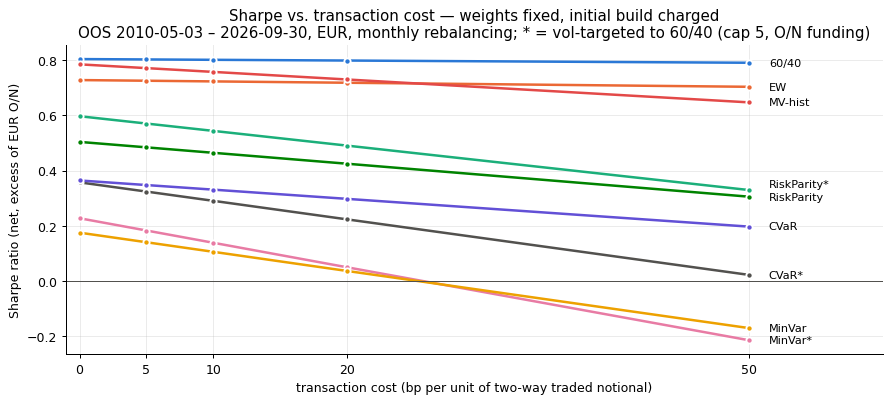

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ly = dodge(sharpe_tc[COSTS[-1]].to_numpy(), 0.045)
for j, m in enumerate(ORDER):
    y = sharpe_tc.loc[m]
    ax.plot(COSTS, y, marker="o", ms=5, lw=2, color=COL[m], markeredgecolor="white", markeredgewidth=1.5)
    ax.annotate(f"{m}", (COSTS[-1], y.iloc[-1]), xytext=(COSTS[-1] + 1.5, ly[j]), textcoords="data", va="center", fontsize=9)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set(xlabel="transaction cost (bp per unit of two-way traded notional)", ylabel="Sharpe ratio (net, excess of EUR O/N)",
       title=f"Sharpe vs. transaction cost — weights fixed, initial build charged\n{SAMPLE}; * = vol-targeted to 60/40 (cap 5, O/N funding)")
ax.set_xticks(COSTS); ax.set_xlim(-1, 60)
fig.tight_layout(); fig.savefig(OUT / "fig_tc_sensitivity.png", dpi=130, bbox_inches="tight"); plt.show()

### 3.1 Turnover and an asset-specific cost scenario

The asset-specific costs below are a **labelled assumption** (rough half-spread plus fees for
liquid ETFs; futures-style costs for the synthetic bond exposures). They are not observed data.
The *stressed* column multiplies them by 3 to mimic crisis-level spreads.

In [6]:
SCEN = pd.Series({"SPY": 2, "VGK": 5, "EWJ": 5, "SHY": 2, "IEF": 2, "TLT": 3, "EUR_CORE7_10_SYN": 5,
                  "JGB7_10_SYN": 8, "LQD": 5, "HYG": 10, "GLD": 3, "DBC": 10}, name="bp (assumption)")
rows = {}
for m in ORDER:
    u, a, s = run(m, cost=10), run(m, cost=SCEN), run(m, cost=SCEN * 3)
    rows[m] = {"TO 2-way p.a.": stats(u)["TO 2-way p.a."], "TO 1-way p.a.": stats(u)["TO 2-way p.a."] / 2,
               "initial TO": u.initial_turnover,
               "TC bp p.a. @10bp": stats(u)["TC bp p.a."], "TC bp p.a. scenario": stats(a)["TC bp p.a."],
               "TC bp p.a. stressed×3": stats(s)["TC bp p.a."],
               "Sharpe @10bp": stats(u)["Sharpe"], "Sharpe scenario": stats(a)["Sharpe"], "Sharpe stressed×3": stats(s)["Sharpe"]}
to_tab = pd.DataFrame(rows).T
to_tab.to_csv(OUT / "turnover_and_asset_costs.csv", float_format="%.4f")
display_scen = SCEN.to_frame().T
print(display_scen.to_string())
to_tab

                 SPY  VGK  EWJ  SHY  IEF  TLT  EUR_CORE7_10_SYN  JGB7_10_SYN  LQD  HYG  GLD  DBC
bp (assumption)    2    5    5    2    2    3                 5            8    5   10    3   10


,TO 2-way p.a.,TO 1-way p.a.,initial TO,TC bp p.a. @10bp,TC bp p.a. scenario,TC bp p.a. stressed×3,Sharpe @10bp,Sharpe scenario,Sharpe stressed×3
60/40,0.206,0.103,1.000,2.668,0.943,2.828,0.801,0.803,0.801
EW,0.234,0.117,1.000,2.948,1.464,4.393,0.723,0.725,0.720
MV-hist,2.780,1.390,1.000,28.408,14.152,42.455,0.757,0.771,0.744
RiskParity*,5.066,2.533,4.479,53.387,23.631,70.893,0.544,0.573,0.526
RiskParity,0.932,0.466,1.000,9.925,4.700,14.100,0.464,0.485,0.448
CVaR*,6.012,3.006,5.000,63.166,33.245,99.736,0.290,0.322,0.252
CVaR,0.757,0.379,1.000,8.181,4.285,12.855,0.331,0.347,0.312
MinVar*,8.245,4.123,5.000,85.502,44.573,133.720,0.139,0.181,0.089
MinVar,1.443,0.721,1.000,15.035,8.033,24.099,0.106,0.138,0.064


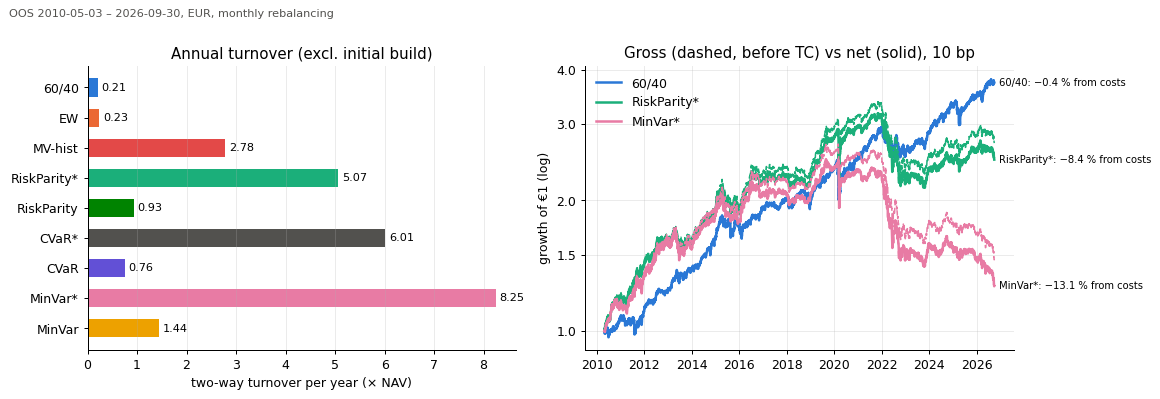

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
y = np.arange(len(ORDER))
ax[0].barh(y, to_tab["TO 2-way p.a."], color=[COL[m] for m in ORDER], height=0.6)
for i, v in enumerate(to_tab["TO 2-way p.a."]):
    ax[0].annotate(f"{v:.2f}", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=9)
ax[0].set_yticks(y, ORDER); ax[0].invert_yaxis(); ax[0].grid(axis="y", visible=False)
ax[0].set(xlabel="two-way turnover per year (× NAV)", title="Annual turnover (excl. initial build)")

for m in ["60/40", "RiskParity*", "MinVar*"]:
    r = runs_tc[(m, 10)]
    g = (1 + r.gross).cumprod(); n = (1 + r.net).cumprod()
    ax[1].plot(g.index, g, color=COL[m], lw=1.2, ls="--")
    ax[1].plot(n.index, n, color=COL[m], lw=2, label=f"{m}")
    ax[1].annotate(f"{m}: −{100 * (1 - n.iloc[-1] / g.iloc[-1]):.1f} % from costs", (n.index[-1], n.iloc[-1]),
                   xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
ax[1].set_yscale("log"); ax[1].set_yticks([1, 1.5, 2, 3, 4], ["1.0", "1.5", "2.0", "3.0", "4.0"]); ax[1].minorticks_off()
ax[1].set(ylabel="growth of €1 (log)", title="Gross (dashed, before TC) vs net (solid), 10 bp")
ax[1].legend(frameon=False, loc="upper left")
fig.suptitle(SAMPLE, x=0.01, ha="left", fontsize=9, color="#52514e", y=0.995)
fig.tight_layout(); fig.savefig(OUT / "fig_turnover_gross_net.png", dpi=130, bbox_inches="tight"); plt.show()

## 4. Funding spread × leverage cap

The vol-targeted strategies borrow to bring their ex-ante volatility up to that of 60/40. Here
the leverage is capped at $L_{max}\in\{1, 1.5, 2, 3\}$ (5 is the original setting), and
borrowing costs the O/N rate plus a spread $s\in\{0,50,100,200\}$ bp p.a., charged only on the
borrowed amount. Costs are 10 bp with the initial build charged.

Reading guide: when $s=0$, leverage scales excess return and volatility by the same factor, so
the Sharpe ratio barely moves. Every basis point of spread comes straight out of the excess
return, at a rate equal to the average amount borrowed.

In [8]:
CAPS, SPREADS = [1.0, 1.5, 2.0, 3.0, 5.0], [0, 50, 100, 200]
ref = run("60/40")
rows = []
for m in ["RiskParity*", "MinVar*", "CVaR*"]:
    for cap in CAPS:
        for s in SPREADS:
            r = run(m, spread=s, cap=cap)
            rows.append({"strategy": m, "L_max": cap, "spread bp": s} | stats(r, ref))
lev_tab = pd.DataFrame(rows).set_index(["strategy", "L_max", "spread bp"])
lev_tab.to_csv(OUT / "leverage_funding_sensitivity.csv", float_format="%.4f")
lev_tab.xs("RiskParity*")[["CAGR %", "vol %", "Sharpe", "Sortino", "MDD %", "ES95 1d %", "TO 2-way p.a.",
                          "funding % p.a.", "avg borrowed", "Memmel p vs 60/40"]]

CAGR %  vol %  ...  avg borrowed  Memmel p vs 60/40
L_max spread bp                 ...                                 
1.000 0           1.735  2.510  ...         0.000              0.008
      50          1.735  2.510  ...         0.000              0.008
      100         1.735  2.510  ...         0.000              0.008
      200         1.735  2.510  ...         0.000              0.008
1.500 0           2.287  3.770  ...         0.500              0.008
      50          2.028  3.771  ...         0.500              0.003
      100         1.770  3.772  ...         0.500              0.001
      200         1.254  3.774  ...         0.501              0.000
2.000 0           2.824  5.034  ...         1.000              0.008
      50          2.304  5.036  ...         1.000              0.002
      100         1.787  5.039  ...         1.000              0.000
      200         0.759  5.043  ...         1.001              0.000
3.000 0           3.833  7.350  ...         1.947              0.008
      50          2.814  7.355  ...         1.948              0.001
      100         1.803  7.361  ...         1.949              0.000
      200        -0.191  7.372  ...         1.952              0.000
5.000 0           5.698 10.047  ...         3.163              0.029
      50          4.020 10.057  ...         3.166              0.003
      100         2.365 10.067  ...         3.169              0.000
      200        -0.875 10.089  ...         3.175              0.000

[20 rows x 10 columns]

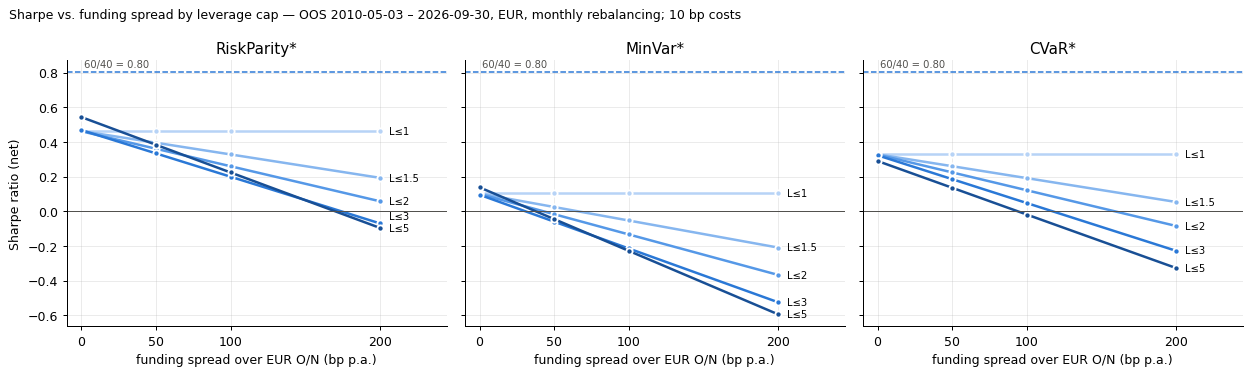

In [9]:
ramp = {1.0: "#b7d3f6", 1.5: "#86b6ef", 2.0: "#5598e7", 3.0: "#2a78d6", 5.0: "#184f95"}
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
sr6040 = stats(ref)["Sharpe"]
for a, m in zip(ax, ["RiskParity*", "MinVar*", "CVaR*"]):
    t = lev_tab.xs(m)["Sharpe"]
    ends = [t.xs(cap, level="L_max").iloc[-1] for cap in CAPS]
    ly = dodge(ends, 0.065)
    for j, cap in enumerate(CAPS):
        y = t.xs(cap, level="L_max")
        a.plot(SPREADS, y, marker="o", ms=5, lw=2, color=ramp[cap], markeredgecolor="white", markeredgewidth=1.5)
        a.annotate(f"L≤{cap:g}", (SPREADS[-1], y.iloc[-1]), xytext=(SPREADS[-1] + 6, ly[j]), textcoords="data", fontsize=8, va="center")
    a.axhline(sr6040, color=COL["60/40"], lw=1.2, ls="--")
    a.annotate(f"60/40 = {sr6040:.2f}", (0, sr6040), xytext=(2, 4), textcoords="offset points", fontsize=8, color="#52514e")
    a.axhline(0, color="#52514e", lw=0.8)
    a.set(title=m, xlabel="funding spread over EUR O/N (bp p.a.)", xticks=SPREADS, xlim=(-10, 245))
ax[0].set_ylabel("Sharpe ratio (net)")
fig.suptitle(f"Sharpe vs. funding spread by leverage cap — {SAMPLE}; 10 bp costs", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "fig_funding_leverage.png", dpi=130, bbox_inches="tight"); plt.show()

In [10]:
# Break-even spread: the s at which the levered strategy's CAGR falls to that of its unlevered version (linear in s on the grid)
rows = {}
for m in ["RiskParity*", "MinVar*", "CVaR*"]:
    base = stats(run(m.rstrip("*")))["CAGR %"]
    for cap in CAPS[1:]:
        y = lev_tab.xs((m, cap), level=["strategy", "L_max"])["CAGR %"]
        slope = (y.iloc[-1] - y.iloc[0]) / SPREADS[-1]
        rows[(m, cap)] = {"CAGR unlevered %": base, "CAGR @ s=0 %": y.iloc[0], "Δ CAGR per 100 bp": 100 * slope,
                          "break-even spread bp": (base - y.iloc[0]) / slope if slope < 0 else np.nan}
be = pd.DataFrame(rows).T
be.to_csv(OUT / "breakeven_spread.csv", float_format="%.4f")
be

CAGR unlevered %  ...  break-even spread bp
RiskParity* 1.500             1.735  ...               106.850
            2.000             1.735  ...               105.416
            3.000             1.735  ...               104.245
            5.000             1.735  ...               120.577
MinVar*     1.500             0.796  ...                15.277
            2.000             0.796  ...                13.589
            3.000             0.796  ...                10.386
            5.000             0.796  ...                19.378
CVaR*       1.500             1.380  ...                72.000
            2.000             1.380  ...                70.403
            3.000             1.380  ...                64.970
            5.000             1.380  ...                52.888

[12 rows x 4 columns]

## 5. Findings

**Engine.** On all nine strategies the NAV identity holds to machine precision, and the
refactored engine reproduces notebook 05 exactly when run with the legacy settings. NAV stays
well above zero; the worst case is levered MinVar* with a 200 bp spread, at 0.40. The leverage
cap is applied **only at rebalance dates**. Between rebalances, positions drift with prices and
gross exposure reached **6.1–6.3×** under the cap of 5. A real risk limit would have to be
checked daily.

**Baseline change.** The annualisation fix raises every Sharpe ratio by about 1.5 %
(60/40: 0.789 → 0.801). Charging the initial build costs 10 bp once for unlevered strategies
and 45–50 bp for the levered ones. No ranking and no significance conclusion changes.

**Transaction costs (RQ3).** Even at **0 bp**, no strategy beats 60/40 (0.80): RP* 0.60,
MV-hist 0.78. Costs cannot erase an edge that was never there; they widen the gap.
The Sharpe lost per 10 bp of cost is proportional to turnover:

| | 60/40 | EW | MV-hist | RP* | MinVar | MinVar* |
|---|---|---|---|---|---|---|
| two-way TO p.a. | 0.21 | 0.23 | 2.78 | 5.07 | 1.44 | 8.25 |
| ΔSharpe per 10 bp | −0.003 | −0.005 | −0.027 | −0.053 | −0.069 | −0.088 |

MinVar and MinVar* have **negative Sharpe above ≈ 25 bp**. Rankings hold up to 20 bp; at 50 bp,
EW overtakes MV-hist and CVaR overtakes CVaR*. The asset-specific cost *scenario* (an assumption
averaging ≈ 5 bp) roughly halves the cost drag compared with a uniform 10 bp. Tripled
("stressed") costs push MinVar to 0.06.

**Funding and leverage.** With zero spread, a fixed leverage cap of 1–3 leaves the Sharpe ratio
unchanged (RP 0.46, CVaR 0.33, MinVar 0.10). Leverage scales risk; it does not add
risk-adjusted return. The higher Sharpe of the original RP* (cap 5: 0.54) comes from
**time-varying** leverage, which was highest in calm, low-volatility bond markets. That
advantage depends on financing at the overnight rate:

* **RP\***: Sharpe 0.54 at 0 bp → 0.38 at 50 bp, which is below unlevered RP (0.46) from about
  25 bp. Its CAGR stays above unlevered RP only while the spread is below **≈ 105–120 bp**.
* **CVaR\***: break-even spread **≈ 50–70 bp**. **MinVar\***: **≈ 10–20 bp**. Its Sharpe turns
  negative at 50 bp for every cap ≥ 1.5.
* At every spread and cap, all levered variants remain significantly below 60/40
  (Memmel p ≤ 0.03).

**Bottom line.** The ranking 60/40 ≥ EW > risk-based rules is robust to every cost and funding
assumption tested. Any result that depends on borrowing 3–5× NAV at the overnight rate
(MinVar*, CVaR*, and to a lesser degree RP*) should be read as an upper bound, not an
implementable return.